In [103]:
import os, glob, re, csv, json, random, multiprocessing as mp
import numpy as np, pandas as pd
import nibabel as nib
from nilearn import datasets
from nilearn.image import resample_to_img
from scipy.optimize import nnls
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import fdrcorrection
from joblib import Parallel, delayed
from collections import defaultdict
from tqdm import tqdm

In [104]:
# Set random seeds for reproducibility
np.random.seed(42)

In [105]:
# ─── 0. PARAMETERS ────────────────────────────────────────────
TRAIT_SETS = {
    "all_13": [
        "Open-minded","feeling Affectionate","Attentive","Assertive",
        "feeling Gloomy","feeling Peaceful","Agreeable","Judging",
        "feeling Angry","feeling Bewildered","Impulsive",
        "Self-disciplined","Contemplating"
    ],
    "mental_8": [
        "feeling Affectionate","feeling Gloomy","feeling Peaceful",
        "feeling Angry","feeling Bewildered","Judging",
        "Contemplating","Attentive"
    ],
    "personality_5": [
        "Open-minded","Agreeable","Assertive",
        "Self-disciplined","Impulsive"
    ],
    "trait_9": [
        "Open-minded","feeling Affectionate","Attentive","Assertive",
        "Agreeable","Judging","feeling Angry","Self-disciplined","Contemplating"
    ]
}
model_key     = "mental_8"
traits        = TRAIT_SETS[model_key]
ALL_TRAIT_STR = [t.replace(" ","_").replace("-","_") for t in traits]

STIM_LABEL    = "notthefallintact"
SHIFT_WINDOW  = 20                  # circular shift ≥ 20 TRs
SMOOTH_SUFFIX = "_no_smoothing"     # "" for smoothed versions
PARCEL_INT    = 68                  # LH_TempPar_1
N_PERM        = 100

In [106]:
root_dir   = r"C:\Users\William\Narratives\fmriprep"
deriv_dir  = os.path.join(root_dir, "derivatives")
cleaned_rt = os.path.join(deriv_dir, f"{STIM_LABEL}_cleaned")
perm_dir   = os.path.join(
    deriv_dir, "RSA_stats", STIM_LABEL, "perm_test_neural_shift")
os.makedirs(perm_dir, exist_ok=True)

In [107]:
# ─── 1. BASIC I/O & SAMPLE IMAGE (for header / affine) ────────
bold_sub = "sub-034"
bold_img = nib.load(
    rf"{cleaned_rt}\{bold_sub}\func\{bold_sub}_task-{STIM_LABEL}"
    rf"_cleaned_desc-masked_bold.nii.gz")
TRS, n_tr = bold_img.header.get_zooms()[3], bold_img.shape[-1]

In [108]:
# ─── 2. SUBJECT / RUN FILTERS ─────────────────────────────────
exclude_subs = {
    "sub-317","sub-335"}
exclude_sub_runs = []

subjects = sorted(
    s for s in os.listdir(cleaned_rt)
    if s.startswith("sub-") and s not in exclude_subs
)
print("Subjects →", ", ".join(subjects))

Subjects → sub-016, sub-034, sub-065, sub-066, sub-084, sub-089, sub-095, sub-096, sub-106, sub-111, sub-132, sub-133, sub-134, sub-135, sub-136, sub-137, sub-139, sub-140, sub-141, sub-142, sub-143, sub-144, sub-145, sub-195, sub-199, sub-268, sub-316, sub-318, sub-319, sub-320, sub-321, sub-322, sub-323, sub-324, sub-325, sub-326, sub-327, sub-328, sub-329, sub-330, sub-331, sub-332, sub-333, sub-334, sub-336, sub-337, sub-338, sub-339, sub-340, sub-341, sub-342, sub-343, sub-344, sub-345


In [109]:
# ─── 3. FETCH / RESAMPLE SCHAEFER ATLAS ───────────────────────
n_rois, yeo_networks, res_mm = 200, 17, 2
schaefer = datasets.fetch_atlas_schaefer_2018(
    n_rois=n_rois, yeo_networks=yeo_networks, resolution_mm=res_mm)
atlas_img  = nib.load(schaefer["maps"])
atlas_res  = resample_to_img(atlas_img, bold_img, interpolation="nearest")
atlas_data = atlas_res.get_fdata().astype(int)

raw_labels = [
    l.decode() if isinstance(l, bytes) else l
    for l in schaefer["labels"]
]
if raw_labels[0].lower() != "background":
    raw_labels.insert(0, "Background")
labels = np.array([l.replace("17Networks_", "") for l in raw_labels])

[fetch_atlas_schaefer_2018] Dataset found in C:\Users\William\nilearn_data\schaefer_2018

C:\Users\William\AppData\Local\Temp\ipykernel_195708\460725599.py:6: FutureWarning: 'force_resample' will be set to 'True' by default in Nilearn 0.13.0.
Use 'force_resample=True' to suppress this warning.
  atlas_res  = resample_to_img(atlas_img, bold_img, interpolation="nearest")
C:\Users\William\AppData\Local\Temp\ipykernel_195708\460725599.py:6: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  atlas_res  = resample_to_img(atlas_img, bold_img, interpolation="nearest")


In [110]:
# ─── 4. LOAD BEHAVIOUR RDMs  (vectorised) ─────────────────────
vec_idx = np.tril_indices(n_tr, k=-1)
behav_rdms = {
    tr: np.load(os.path.join(
        deriv_dir, "RDMs_behavior",
        f"{STIM_LABEL}_{tstr}_RDM{SMOOTH_SUFFIX}.npy"))[vec_idx]
    for tr, tstr in zip(traits, ALL_TRAIT_STR)
}
X_base = np.column_stack([np.ones(vec_idx[0].shape[0])] +
                         [behav_rdms[t] for t in traits])

# ─── 5. LOAD SUBJECT-RUN BETAS (observed sₖ) ──────────────────
csv_pat = os.path.join(
    deriv_dir, "RSA_stats", STIM_LABEL, "multi_regression",
    "subject_results",
    f"*_{STIM_LABEL}_multi_parcel_RSA_NNLS_{model_key}{SMOOTH_SUFFIX}.csv")
df_obs = pd.concat(
    (pd.read_csv(fn).assign(unit=lambda d: d.subject + "_" + d.run.astype(str)))
    for fn in glob.glob(csv_pat)
)
trait_cols = ALL_TRAIT_STR
for k in range(1, len(trait_cols)+1):
    df_obs[f"s{k}"] = np.sort(df_obs[trait_cols].values, axis=1)[:, ::-1][:, :k].sum(1)

observed = {
    k: df_obs.groupby("parcel_num")[f"s{k}"].mean()
    for k in range(1, len(trait_cols)+1)
}

# ─── 6. CACHE VECTORISED NEURAL RDMs ──────────────────────────
neural_cache = {}
for sub in tqdm(subjects, desc="Caching neural RDMs"):
    func_dir = os.path.join(cleaned_rt, sub, "func")
    bold_glob = (
        glob.glob(os.path.join(
            func_dir, f"{sub}_task-{STIM_LABEL}_run-*_*cleaned_desc-masked_bold.nii.gz"))
        + glob.glob(os.path.join(
            func_dir, f"{sub}_task-{STIM_LABEL}_cleaned_desc-masked_bold.nii.gz"))
    )
    for bf in sorted(bold_glob):
        run = re.search(r"_run-(\d+)_", os.path.basename(bf))
        run = run.group(1) if run else "NA"
        if (sub, run) in exclude_sub_runs:
            continue
        img      = nib.load(bf)
        bold_dat = img.get_fdata()
        atlas_r  = resample_to_img(atlas_img, img, interpolation="nearest")
        a_dat    = atlas_r.get_fdata().astype(int)

        for pid in range(1, n_rois+1):
            msk = a_dat == pid
            if not msk.any():
                continue
            corr = np.corrcoef(bold_dat[msk, :].T)
            neural_cache[(sub, run, pid)] = (1 - corr).astype(np.float32)


# ─── freeze order of items & pre-draw all shifts ──────────────
neural_items = list(neural_cache.items())       # deterministic order
N_ITEMS      = len(neural_items)

rng = np.random.RandomState(42)                 # legacy generator
shifts = rng.randint(
    SHIFT_WINDOW, n_tr - SHIFT_WINDOW,
    size=(N_PERM, N_ITEMS)                      # N_PERM rows
).astype(np.int16)                              # small + picklable


# ─── 7. PERMUTATION WORKER  ──────────────────
def run_perm(p_index: int):
    row_shifts = shifts[p_index]                # length = N_ITEMS
    sums   = {k: defaultdict(float) for k in range(1, len(trait_cols)+1)}
    counts = {k: defaultdict(int)   for k in range(1, len(trait_cols)+1)}
    subj_loc = defaultdict(list)

    for idx, ((sub, run, pid), mat) in enumerate(neural_items):
        shift = int(row_shifts[idx])

        # --- exact 2-D circular shift, then vectorise ---
        rolled = np.roll(np.roll(mat, shift, axis=0), shift, axis=1)
        y      = rolled[vec_idx]                # lower-triangular 1-D view

        beta, _ = nnls(X_base, y)
        betas   = beta[1:]
        top     = np.sort(betas)[::-1]

        for k in range(1, len(trait_cols)+1):
            s_k = top[:k].sum()
            sums[k][pid]   += s_k
            counts[k][pid] += 1
            if pid == PARCEL_INT and k == 1:
                subj_loc[(sub, run)].append(s_k)
    return sums, counts, subj_loc

# ─── 8. RUN PERMUTATIONS IN PARALLEL ──────────────────────────
n_jobs = mp.cpu_count()

perm_out = Parallel(n_jobs=n_jobs, backend="loky", batch_size=1)(
    delayed(run_perm)(perm_idx) for perm_idx in range(N_PERM)
)

# ─── 9. REDUCE PERMUTATION RESULTS ────────────────────────────
nulls = {k: defaultdict(list) for k in range(1, len(trait_cols)+1)}
subj_perm_vals = defaultdict(list)

for sums, counts, subj_local in perm_out:
    for k in sums:
        for pid in sums[k]:
            nulls[k][pid].append(sums[k][pid] / counts[k][pid])
    for key, lst in subj_local.items():
        subj_perm_vals[key].extend(lst)


# ─── 10. SAVE PER-SUBJECT PERM MATRIX FOR PARCEL_INT ──────────
subjects_unique = sorted({s for (s, _) in subj_perm_vals})
perm_mat = np.vstack([
    np.mean([subj_perm_vals[(s, r)] for (ss, r) in subj_perm_vals if ss == s], axis=0)
    for s in subjects_unique
]).T.astype(np.float32)      # shape (N_PERM, n_subj)

np.save(os.path.join(
    perm_dir, f"{STIM_LABEL}_parcel{PARCEL_INT}_subject_s1_perms.npy"), perm_mat)

obs_s1 = df_obs.query("parcel_num == @PARCEL_INT") \
        .groupby("subject")["s1"].mean().reindex(subjects_unique).values.astype(np.float32)
np.save(os.path.join(
    perm_dir, f"{STIM_LABEL}_parcel{PARCEL_INT}_observed_s1.npy"), obs_s1)


# ─── 11. P-VALUES FOR ALL (k, parcel) COMBINATIONS ────────────
rows = []
for k in range(1, len(trait_cols)+1):
    for pid, obs_val in observed[k].items():
        null_dist = np.array(nulls[k][pid])
        pval = (np.sum(null_dist >= obs_val) + 1) / (N_PERM + 1)
        rows.append((k, pid, obs_val, pval, pval < .05))
df_perm = pd.DataFrame(rows, columns=[
    "k", "parcel_num", "observed_s", "p_value", "sig_p05"
])
df_perm["parcel_label"] = df_perm.parcel_num.map(
    dict(enumerate(labels[1:], start=1)))

out_csv = os.path.join(
    perm_dir, f"{STIM_LABEL}_perm_test_{model_key}_allks{SMOOTH_SUFFIX}.csv")
df_perm.to_csv(out_csv, index=False)
print("✅ Permutation CSV saved →", out_csv)


# ─── 12. OPTIONAL QUICK REPORT ────────────────────────────────
print(df_perm.query("k == 1 and sig_p05").head())

Caching neural RDMs:   0%|          | 0/54 [00:00<?, ?it/s]C:\Users\William\AppData\Local\Temp\ipykernel_195708\1465325133.py:47: FutureWarning: 'force_resample' will be set to 'True' by default in Nilearn 0.13.0.
Use 'force_resample=True' to suppress this warning.
  atlas_r  = resample_to_img(atlas_img, img, interpolation="nearest")
C:\Users\William\AppData\Local\Temp\ipykernel_195708\1465325133.py:47: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  atlas_r  = resample_to_img(atlas_img, img, interpolation="nearest")
Caching neural RDMs:   2%|▏         | 1/54 [00:01<01:25,  1.62s/it]C:\Users\William\AppData\Local\Temp\ipykernel_195708\1465325133.py:47: FutureWarning: 'force_resample' will be set to 'True' by default in Nilearn 0.13.0.
Use 'force_resample=True' to suppress th

✅ Permutation CSV saved → C:\Users\William\Narratives\fmriprep\derivatives\RSA_stats\notthefallintact\perm_test_neural_shift\notthefallintact_perm_test_mental_8_allks_no_smoothing.csv
Empty DataFrame
Columns: [k, parcel_num, observed_s, p_value, sig_p05, parcel_label]
Index: []


perm.shape = (100, 54)
obs.shape  = (54,)
Parcel-68, k=1, overall p-value (should be ~0.01): 1.0000


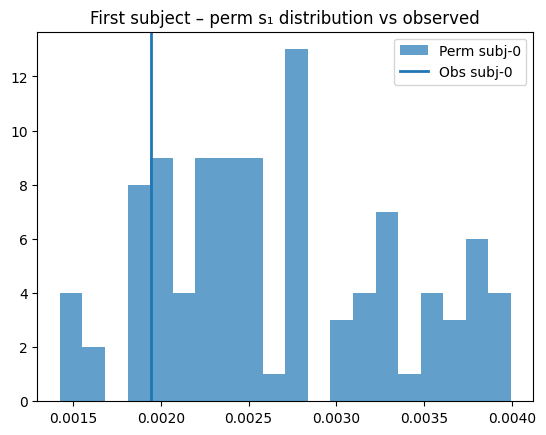

In [111]:
perm_path   = os.path.join(perm_dir, f"{STIM_LABEL}_parcel{PARCEL_INT}_subject_s1_perms.npy")
obs_path    = os.path.join(perm_dir, f"{STIM_LABEL}_parcel{PARCEL_INT}_observed_s1.npy")

# 1) Load arrays
perm = np.load(perm_path)         # shape (n_perm, n_subj)
obs  = np.load(obs_path)          # shape (n_subj,)

print(f"perm.shape = {perm.shape}")
print(f"obs.shape  = {obs.shape}")

# 2) Basic shape & dtype checks
n_perm, n_subj = perm.shape
assert obs.shape == (n_subj,),  "obs vector length must match #columns of perm"
assert perm.dtype == np.float32 and obs.dtype == np.float32, "dtype mismatch"
assert not np.isnan(perm).any(), "NaNs found in perm matrix"
assert not np.isnan(obs).any(),  "NaNs found in obs vector"

# 3) Subjects in same order?  (Optional, only if you saved them)
# If you wrote 'subjects_unique' to disk:
# subj_order = np.loadtxt(os.path.join(perm_dir, "subjects_order.txt"), dtype=str)
# print("First 5 subjects:", subj_order[:5])

# 4) Quick “global” p-value check (mean-across-subjects)
perm_means = perm.mean(axis=1)        # shape (n_perm,)
obs_mean   = obs.mean()               # scalar
p_val = ((perm_means >= obs_mean).sum() + 1) / (n_perm + 1)
print(f"Parcel-{PARCEL_INT}, k=1, overall p-value (should be ~0.01): {p_val:.4f}")

# 5) Quick per-subject distribution sanity (optional)
import matplotlib.pyplot as plt
plt.hist(perm[:,0], bins=20, alpha=.7, label='Perm subj-0'); plt.axvline(obs[0], lw=2,label='Obs subj-0')
plt.title('First subject – perm s₁ distribution vs observed'); plt.legend(); plt.show()

In [112]:
observed_df = pd.DataFrame(observed)
print(observed_df)

                   1         2         3         4         5         6  \
parcel_num                                                               
1           0.002182  0.003733  0.004835  0.005577  0.005961  0.006098   
2           0.002362  0.003901  0.004989  0.005711  0.006080  0.006223   
3           0.002200  0.003660  0.004786  0.005556  0.005952  0.006122   
4           0.002281  0.003751  0.004899  0.005566  0.005945  0.006079   
5           0.002254  0.003721  0.004759  0.005431  0.005825  0.005977   
...              ...       ...       ...       ...       ...       ...   
196         0.002038  0.003359  0.004308  0.004957  0.005329  0.005440   
197         0.002267  0.003740  0.004734  0.005385  0.005753  0.005886   
198         0.002262  0.003656  0.004644  0.005267  0.005633  0.005792   
199         0.002212  0.003712  0.004800  0.005479  0.005873  0.006014   
200         0.002288  0.003761  0.004774  0.005480  0.005859  0.005987   

                   7         8  
parc

In [113]:
df_perm = pd.read_csv(out_csv)
print(df_perm.info())
print(df_perm.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   k             1600 non-null   int64  
 1   parcel_num    1600 non-null   int64  
 2   observed_s    1600 non-null   float64
 3   p_value       1600 non-null   float64
 4   sig_p05       1600 non-null   bool   
 5   parcel_label  1600 non-null   object 
dtypes: bool(1), float64(2), int64(2), object(1)
memory usage: 64.2+ KB
None
   k  parcel_num  observed_s   p_value  sig_p05          parcel_label
0  1           1    0.002182  1.000000    False    LH_VisCent_ExStr_1
1  1           2    0.002362  0.980198    False    LH_VisCent_ExStr_2
2  1           3    0.002200  1.000000    False  LH_VisCent_Striate_1
3  1           4    0.002281  0.950495    False    LH_VisCent_ExStr_3
4  1           5    0.002254  0.990099    False    LH_VisCent_ExStr_4


In [114]:
# Load CSV file 
perm_csv_path = f"/Volumes/Passport/fmriprep/derivatives/RSA_stats/{STIM_LABEL}/perm_test_neural_shift/{STIM_LABEL}_perm_test_{model_key}_allks{SMOOTH_SUFFIX}.csv"
df_perm1 = pd.read_csv(perm_csv_path)

# Filter to only the k=1 results
df_perm1['k'] = df_perm1['k'].astype(int)
df_k1 = df_perm1[df_perm1['k'] == 1].copy()
df_k1['parcel_num'] = df_k1['parcel_num'].astype(int)


# 1) Extract the integer parcel map
atlas_data = atlas_resampled.get_fdata().astype(int)

# 2) Create maps
p_map               = np.zeros(atlas_data.shape, dtype=float)               # unthresholded
p_map_thresholded   = np.full(atlas_data.shape, np.nan, dtype=float)        # use NaN for masking
s_map               = np.zeros(atlas_data.shape, dtype=float)               # unthresholded
s_map_thresholded   = np.zeros(atlas_data.shape, dtype=float)               # 0 for non-sig

# 3) Fill in each parcel
for _, row in df_k1.iterrows():
    pid  = int(row['parcel_num'])
    pval = float(row['p_value'])
    sval = float(row['observed_s'])

    p_map[atlas_data == pid] = pval
    s_map[atlas_data == pid] = sval

    if pval < 0.05:
        p_map_thresholded[atlas_data == pid] = pval
        s_map_thresholded[atlas_data == pid] = sval

# 4) Wrap and save NIfTI images
p_img = nib.Nifti1Image(p_map, atlas_resampled.affine, atlas_resampled.header)
nib.save(p_img, os.path.join(perm_dir, f"{STIM_LABEL}_perm_pmap_{model_key}_k1{SMOOTH_SUFFIX}.nii.gz"))
print("✅ unthresholded k=1 p-value map saved")

p_img_thresh = nib.Nifti1Image(p_map_thresholded, atlas_resampled.affine, atlas_resampled.header)
nib.save(p_img_thresh, os.path.join(perm_dir, f"{STIM_LABEL}_perm_pmap_{model_key}_k1_thresh05{SMOOTH_SUFFIX}.nii.gz"))
print("✅ thresholded k=1 p-value map (NaN-masked) saved")

s_img = nib.Nifti1Image(s_map, atlas_resampled.affine, atlas_resampled.header)
nib.save(s_img, os.path.join(perm_dir, f"{STIM_LABEL}_perm_smap_{model_key}_k1{SMOOTH_SUFFIX}.nii.gz"))
print("✅ k=1 observed s-value map saved")

s_img_thresh = nib.Nifti1Image(s_map_thresholded, atlas_resampled.affine, atlas_resampled.header)
nib.save(s_img_thresh, os.path.join(perm_dir, f"{STIM_LABEL}_perm_smap_{model_key}_k1_thresh05{SMOOTH_SUFFIX}.nii.gz"))
print("✅ thresholded k=1 s-value map saved")

# 5) Save -p map for MRIcroGL visualization
neg_p_map = -1.0 * p_map

neg_p_img = nib.Nifti1Image(neg_p_map, atlas_resampled.affine, atlas_resampled.header)
nib.save(neg_p_img, os.path.join(perm_dir, f"{STIM_LABEL}_perm_neg_pmap_{model_key}_k1{SMOOTH_SUFFIX}.nii.gz"))
print("✅ negative p-value map (p * -1) saved for visualization")

# Optional: Summary for verification
n_sig_parcels = df_k1[df_k1['p_value'] < 0.05]['parcel_num'].nunique()
print(f"Significant parcels (p < 0.05): {n_sig_parcels}")
print("Nonzero thresholded voxels in s_map:", np.count_nonzero(s_map_thresholded))
print("Non-NaN voxels in thresholded p_map:", np.count_nonzero(~np.isnan(p_map_thresholded)))



FileNotFoundError: [Errno 2] No such file or directory: '/Volumes/Passport/fmriprep/derivatives/RSA_stats/notthefallintact/perm_test_neural_shift/notthefallintact_perm_test_mental_8_allks_no_smoothing.csv'